## AmesHousing
#### Schritt 1: Initialisierung und Laden
Importieren Sie die erforderlichen Data-Science-Bibliotheken und laden Sie den tabulatorgetrennten Datensatz in einen pandas-DataFrame.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore", message=".*Falling back to prediction using DMatrix.*")

train_dataset = pd.read_csv("AmesHousing.csv", sep='\t')

display(train_dataset.head())

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


#### Schritt 2: Datenprüfung
Überprüfen Sie die Datentypen, die Zeilenanzahl und die Zusammenfassungsstatistiken (Minimum, Maximum, Perzentile), um sich einen Überblick über den Umfang des Datensatzes zu verschaffen.

In [2]:
train_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

In [3]:
display(train_dataset.describe())

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2907.000000,...,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,101.896801,...,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,179.112611,...,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,164.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,...,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


#### Schritt 3: Umgang mit fehlenden Werten
Spalten mit fehlenden Daten werden identifiziert. Spalten, die fast vollständig leer sind (wie „Pool QC“ oder „Fence“), werden verworfen, da sie eine Varianz nahe Null aufweisen. Die verbleibenden fehlenden Werte werden imputiert (bei Textdaten mit „Keine“ und bei Zahlen mit 0 ergänzt).

In [4]:
missing_values = train_dataset.isna().sum()

print(missing_values[missing_values > 0].sort_values(ascending=False))

Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Qual        159
Garage Cond        159
Garage Yr Blt      159
Garage Finish      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Cond           80
Bsmt Qual           80
BsmtFin Type 1      80
Mas Vnr Area        23
Bsmt Full Bath       2
Bsmt Half Bath       2
BsmtFin SF 1         1
BsmtFin SF 2         1
Electrical           1
Total Bsmt SF        1
Bsmt Unf SF          1
Garage Area          1
Garage Cars          1
dtype: int64


In [5]:
train_dataset = train_dataset.drop(columns=["Pool QC"])
train_dataset = train_dataset.drop(columns=["Misc Feature"])
train_dataset = train_dataset.drop(columns=["Alley"])
train_dataset = train_dataset.drop(columns=["Fence"])

In [6]:
categorical_cols = train_dataset.select_dtypes(include=['object', 'str']).columns
train_dataset[categorical_cols] = train_dataset[categorical_cols].fillna("None")

numerical_cols = train_dataset.select_dtypes(include=['int64', 'float64']).columns
train_dataset[numerical_cols] = train_dataset[numerical_cols].fillna(0)

print("Gesamtzahl der verbleibenden fehlenden Werte:",  train_dataset.isna().sum().sum())

Gesamtzahl der verbleibenden fehlenden Werte: 0


## Explorative Visualisierungen

#### Histogramm
Ein Histogramm mit einer KDE-Kurve wurde erstellt, um die Häufigkeitsverteilung einer einzelnen numerischen Variable zu visualisieren. Dies zeigt auf einen Blick, wo sich die meisten Datenpunkte häufen und ob die Verteilung Schiefen aufweist.

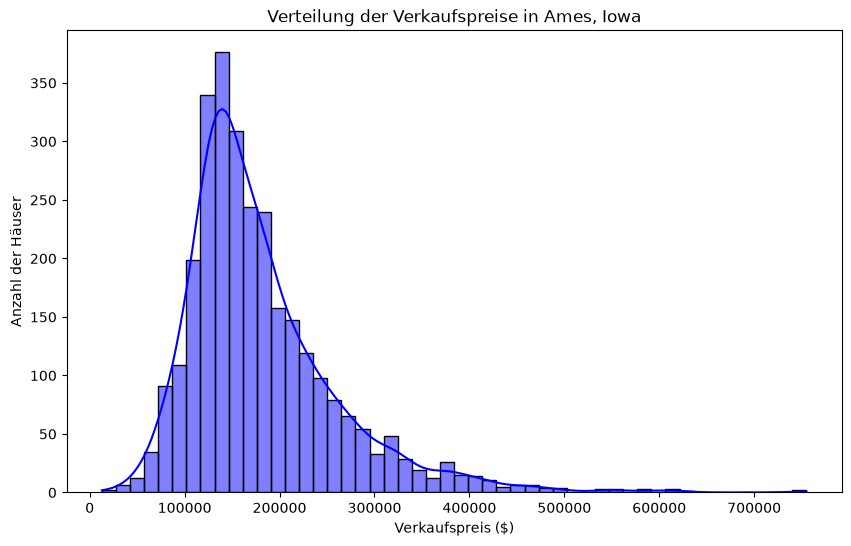

In [7]:
plt.figure(figsize=(10, 6))
sns.histplot(train_dataset['SalePrice'], kde=True, bins=50, color='blue')
plt.title('Verteilung der Verkaufspreise in Ames, Iowa')
plt.xlabel('Verkaufspreis ($)')
plt.ylabel('Anzahl der Häuser')
plt.show()

Die Verteilung der Verkaufspreise im Ames-Datensatz ist stark rechtsschief. Die überwiegende Mehrheit der Häuser wird in der Spanne von 100.000 bis 200.000 Dollar verkauft, wobei sich die höchste Konzentration (der Höhepunkt der Verteilung) um 150.000 bis 160.000 Dollar konzentriert. Ein langer rechter Schwanz deutet auf eine kleine Untergruppe von Luxusimmobilien hin, die für 300.000 bis über 500.000 Dollar verkauft werden, was den Durchschnittspreis (Mittelwert) deutlich über den Medianpreis zieht.

#### Boxplot
Es wurde ein Boxplot generiert, um die Verteilung einer numerischen Variable über verschiedene Kategorien hinweg zu vergleichen. Dadurch lassen sich der Median, die Streuung der mittleren 50 Prozent der Daten (Quartile) sowie mögliche Ausreißer in den jeweiligen Gruppen direkt ablesen.

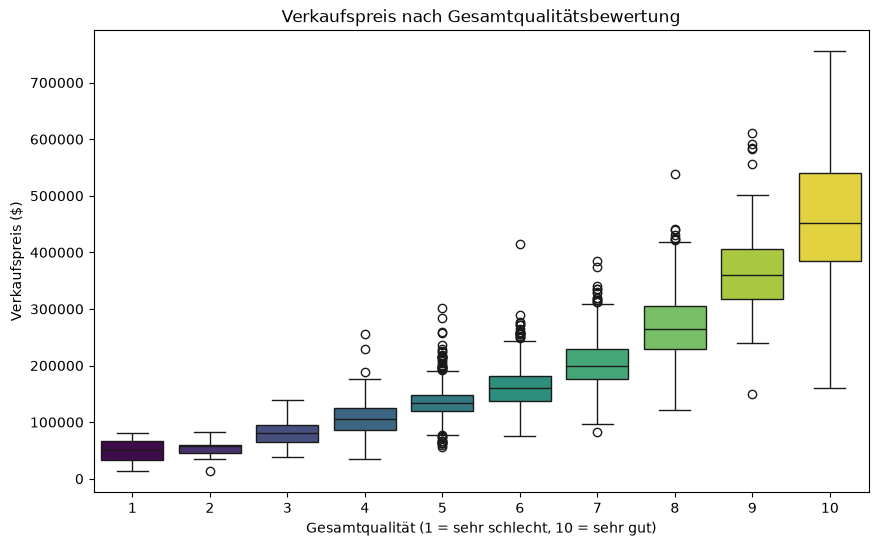

In [8]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    x='Overall Qual',
    y='SalePrice',
    data=train_dataset,
    palette='viridis',
    hue='Overall Qual',
    legend=False
)
plt.title('Verkaufspreis nach Gesamtqualitätsbewertung')
plt.xlabel('Gesamtqualität (1 = sehr schlecht, 10 = sehr gut)')
plt.ylabel('Verkaufspreis ($)')
plt.show()

Es besteht ein eindeutiger, positiver und nichtlinearer (nahezu exponentieller) Zusammenhang zwischen der Gesamtqualitätsbewertung (1–10) und dem Verkaufspreis. Mit steigender Qualitätsbewertung steigt der Medianverkaufspreis deutlich an. Die Streuung der Daten (die Größe der Boxen) nimmt bei Immobilien höherer Qualität (Bewertungen 8, 9 und 10) ebenfalls erheblich zu, was darauf hindeutet, dass die Preise für Luxusimmobilien wesentlich stärker schwanken und stark von zusätzlichen Faktoren wie Größe oder Lage abhängen. Darüber hinaus gibt es mehrere hochpreisige Ausreißer, die sich auf die Qualitätsstufen „durchschnittlich“ bis „gut“ (Bewertungen 5 bis 8) konzentrieren; dabei handelt es sich um Immobilien, die für deutlich mehr verkauft wurden als der für ihren Zustand typische Preisbereich.

#### Scatterplot
Ein Streudiagramm wurde gezeichnet, um die Beziehung zwischen zwei numerischen Variablen darzustellen. Jeder Punkt repräsentiert einen Datensatz, wodurch Muster, Häufungen oder Korrelationen zwischen den beiden Merkmalen sichtbar werden.

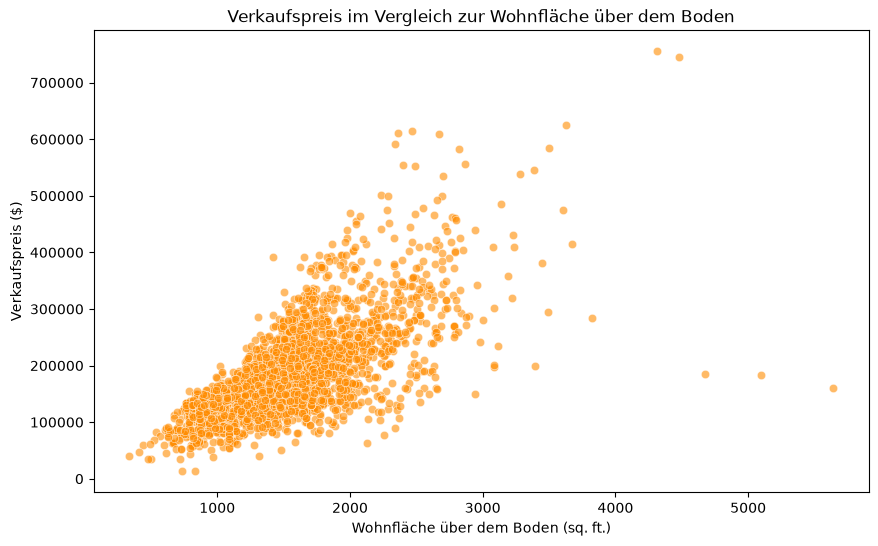

In [9]:
plt.figure(figsize=(10, 6))
# alpha=0.6 makes the dots slightly transparent so we can see where they overlap
sns.scatterplot(x='Gr Liv Area', y='SalePrice', data=train_dataset, alpha=0.6, color='darkorange')
plt.title('Verkaufspreis im Vergleich zur Wohnfläche über dem Boden')
plt.xlabel('Wohnfläche über dem Boden (sq. ft.)')
plt.ylabel('Verkaufspreis ($)')
plt.show()

Die Daten zeigen eine starke positive Korrelation zwischen der Wohnfläche eines Hauses über dem Boden und seinem Verkaufspreis. Mit zunehmender Quadratfußzahl steigen die Preise stetig an, doch die Grafik verdeutlicht auch bekannte extreme Ausreißer innerhalb des Ames-Datensatzes – insbesondere riesige Häuser (über 4.000 Quadratfuß), die zu ungewöhnlich niedrigen Preisen verkauft wurden, oft aufgrund ihres schlechten Zustands oder atypischer Bebauungsvorschriften.

In [10]:
# Filter out the massive outliers
train_dataset = train_dataset[train_dataset['Gr Liv Area'] < 4000]

#### Heatmap
Eine Heatmap wurde verwendet, um die Korrelationsmatrix der Variablen farblich zu kodieren. Starke positive oder negative Zusammenhänge zwischen verschiedenen Merkmalen lassen sich so durch die jeweilige Farbintensität schnell identifizieren.

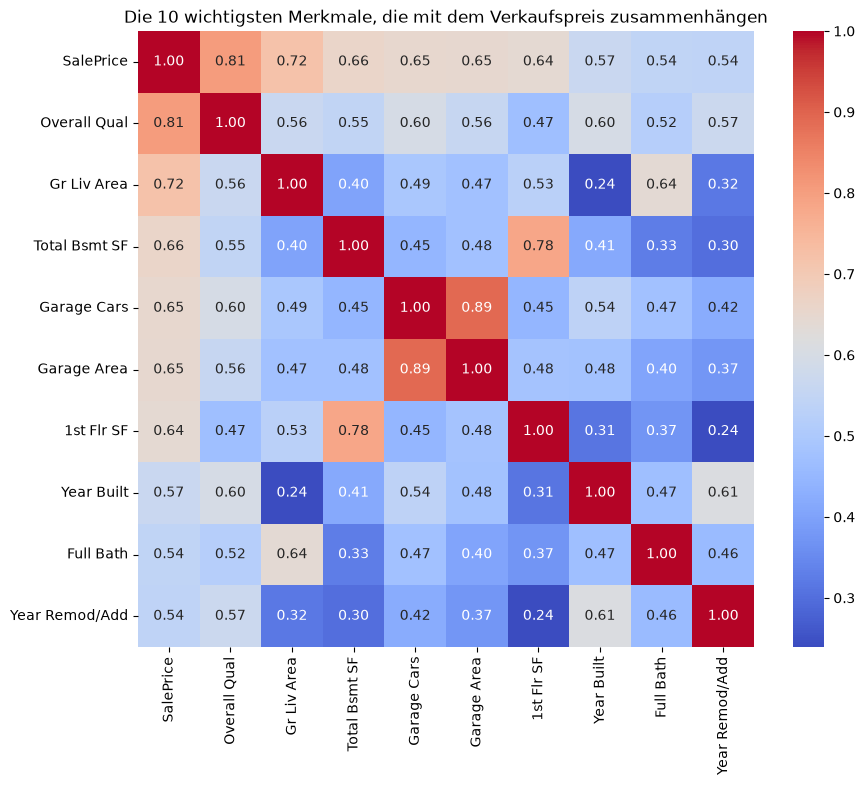

In [11]:
plt.figure(figsize=(10, 8))

numeric_data = train_dataset.select_dtypes(include=['int64', 'float64'])

corr_matrix = numeric_data.corr()

top_corr_cols = corr_matrix.nlargest(10, 'SalePrice')['SalePrice'].index

top_corr_matrix = numeric_data[top_corr_cols].corr()
sns.heatmap(top_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title('Die 10 wichtigsten Merkmale, die mit dem Verkaufspreis zusammenhängen')
plt.show()

Die Heatmap zeigt, dass „Overall Qual“ (Korrelation ~0,8) und „Gr Liv Area“ (Korrelation ~0,7) die stärksten linearen Prädiktoren für den Verkaufspreis sind. Sie macht zudem eine erhebliche Multikollinearität zwischen den Prädiktorvariablen deutlich; so korreliert beispielsweise „Garage Cars“ nahezu perfekt mit „Garage Area“, und „Total Bsmt SF“ korreliert stark mit „1st Flr SF“, was bedeutet, dass diese gepaarten Merkmale redundante Informationen liefern und bestimmte Vorhersagemodelle verzerren könnten, wenn dies nicht berücksichtigt wird.

#### Lineare Regression
Ein Streudiagramm wurde um eine Regressionsgerade ergänzt, um den linearen Trend zwischen einer unabhängigen und einer abhängigen Variable zu modellieren. Die Gerade veranschaulicht die rechnerisch bestmögliche Anpassung an die Datenpunkte und hilft dabei, die zugrundeliegende Entwicklung abzuschätzen.

Die angepasste Regressionsgerade bestätigt den Aufwärtstrend der Basislinie und quantifiziert den durchschnittlichen Anstieg des Verkaufspreises in Dollar pro zusätzlichem Quadratfuß Wohnfläche. Bei größeren Wohnflächen weichen die Datenpunkte jedoch zunehmend stärker von der Geraden ab (Heteroskedastizität), was zeigt, dass ein einfaches lineares Modell bei größeren Immobilien an Vorhersagegenauigkeit verliert, da dort Luxusausstattung, Lage und Zustand einen wesentlich größeren Einfluss haben als die reine Wohnfläche.

In [12]:
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve, f1_score
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.preprocessing import label_binarize

X = train_dataset.drop(columns=['SalePrice'])
y_continuous = train_dataset['SalePrice']

for col in X.select_dtypes(include=['object', 'string']).columns:
    X[col] = X[col].astype('category')

bins = [0, 100000, 130000, 180000, 250000, 400000, np.inf]
labels = [0, 1, 2, 3, 4, 5]
y = pd.cut(y_continuous, bins=bins, labels=labels, right=False)

sample_weights = compute_sample_weight(class_weight='balanced', y=y)

Die kontinuierliche Variable SalePrice wurde mithilfe von pd.cut in die geforderten sechs Preisklassen diskretisiert. Da in typischen Immobilienmärkten mittlere Preisklassen deutlich stärker vertreten sind als extrem günstige oder teure Häuser, entsteht ein Klassenungleichgewicht (Class Imbalance). Um dies zu beheben, werden im Vorfeld sample_weights berechnet, die dem Modell später beim Training übergeben werden. Dadurch werden Fehlklassifikationen in selteneren Klassen stärker bestraft.

In [13]:
X_train_10, X_test_10, y_train_10, y_test_10 = train_test_split(X, y, test_size=0.1, random_state=42)
X_train_10_strat, X_test_10_strat, y_train_10_strat, y_test_10_strat = train_test_split(X, y, test_size=0.1, stratify=y, random_state=42)

X_train_20, X_test_20, y_train_20, y_test_20 = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_20_strat, X_test_20_strat, y_train_20_strat, y_test_20_strat = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

xgb_base = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=6,
    tree_method='hist',
    device='cuda',
    enable_categorical=True,
    random_state=42
)

kf_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
kf_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

cv_5_scores = cross_val_score(xgb_base, X, y, cv=kf_5, scoring='f1_macro')
cv_10_scores = cross_val_score(xgb_base, X, y, cv=kf_10, scoring='f1_macro')

print(f"CV k=5 Macro F1: {cv_5_scores.mean():.4f} (+/- {cv_5_scores.std():.4f})")
print(f"CV k=10 Macro F1: {cv_10_scores.mean():.4f} (+/- {cv_10_scores.std():.4f})")

CV k=5 Macro F1: 0.7340 (+/- 0.0349)
CV k=10 Macro F1: 0.7400 (+/- 0.0289)


Stratifizierung: Ohne Stratifizierung (stratify=None) laufen wir bei kleinen Datensätzen oder starkem Ungleichgewicht Gefahr, dass seltene Klassen (z.B. >= 400.000 USD) im Testset über- oder unterrepräsentiert sind. Die Stratifizierung stellt sicher, dass die Klassenverteilung im Train- und Test-Split identisch zur Gesamtverteilung bleibt. Ein 20%-Split bietet eine robustere Evaluierung, während ein 10%-Split dem Modell mehr Trainingsdaten überlässt.</br> Bias-Variance Tradeoff bei K-Fold: Bei $k=5$ ist das Validierungsset pro Fold größer, was zu einer stabileren Schätzung der Modellgüte (geringere Varianz), aber potenziell einem höheren Bias führt (da jeweils nur 80% der Daten fürs Training genutzt werden). Bei $k=10$ wächst das Trainingsset auf 90% pro Fold, wodurch der Bias der Fehlerschätzung sinkt. Da die Testsets pro Fold aber kleiner werden, kann die Varianz der Metriken zwischen den einzelnen Folds steigen, besonders bei kleinen Minderheitsklassen.

Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.71      0.73        48
           1       0.70      0.75      0.73       102
           2       0.81      0.79      0.80       207
           3       0.79      0.80      0.80       137
           4       0.81      0.84      0.82        79
           5       0.86      0.50      0.63        12

    accuracy                           0.78       585
   macro avg       0.79      0.73      0.75       585
weighted avg       0.78      0.78      0.78       585



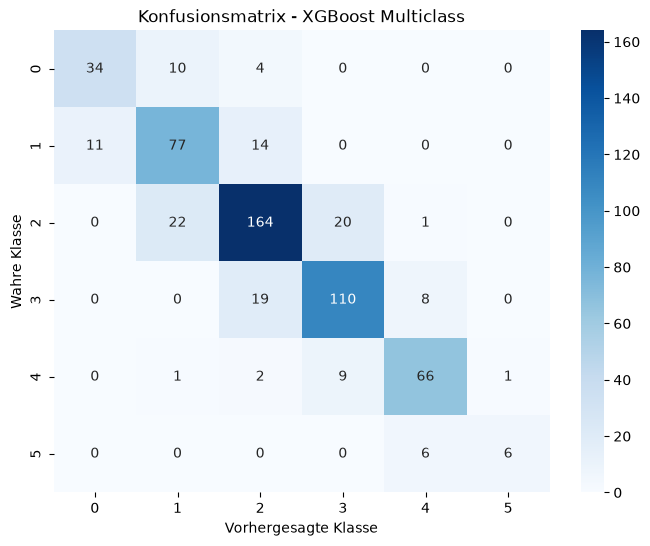

In [14]:
weights_train = compute_sample_weight('balanced', y_train_20_strat)

xgb_base.fit(X_train_20_strat, y_train_20_strat, sample_weight=weights_train)
y_pred = xgb_base.predict(X_test_20_strat)
y_pred_proba = xgb_base.predict_proba(X_test_20_strat)

print("Classification Report:\n", classification_report(y_test_20_strat, y_pred))

plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test_20_strat, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Konfusionsmatrix - XGBoost Multiclass')
plt.ylabel('Wahre Klasse')
plt.xlabel('Vorhergesagte Klasse')
plt.show()

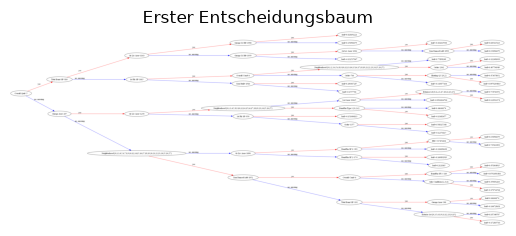

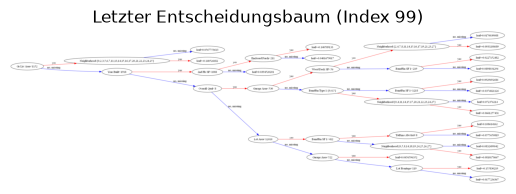

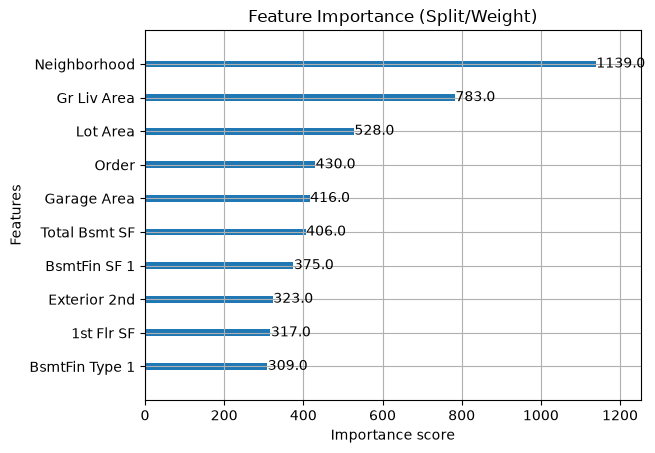

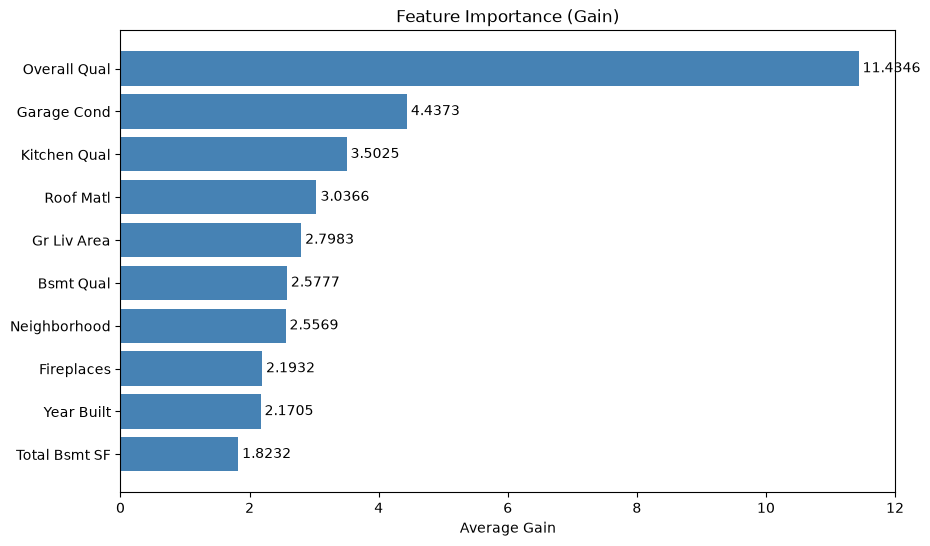

In [15]:
xgb.plot_tree(xgb_base, tree_idx=0, rankdir='LR')
plt.title('Erster Entscheidungsbaum')
plt.show()

last_tree_idx = xgb_base.n_estimators - 1 if xgb_base.n_estimators is not None else 99

xgb.plot_tree(xgb_base, tree_idx=last_tree_idx, rankdir='LR')
plt.title(f'Letzter Entscheidungsbaum (Index {last_tree_idx})')
plt.show()

xgb.plot_importance(xgb_base, importance_type='weight', max_num_features=10, title="Feature Importance (Split/Weight)")
plt.show()

importance_gain = xgb_base.get_booster().get_score(importance_type='gain')
df_imp_gain = pd.DataFrame(list(importance_gain.items()), columns=['Feature', 'Gain'])
df_imp_gain = df_imp_gain.sort_values(by='Gain', ascending=True).tail(10)

plt.figure(figsize=(10, 6))
bars = plt.barh(df_imp_gain['Feature'], df_imp_gain['Gain'], color='steelblue')
plt.title("Feature Importance (Gain)")
plt.xlabel("Average Gain")

for bar in bars:
    width = bar.get_width()
    plt.text(width, bar.get_y() + bar.get_height() / 2, f' {width:.4f}', va='center')
plt.show()

Bäume: Der erste Baum repräsentiert die anfängliche, noch grobe Anpassung an die Residuen der Daten, während spätere Bäume sich auf die verbliebenen, schwer zu klassifizierenden Fehler fokussieren.

Gain vs. Split: Split (Weight) zeigt lediglich die reine Häufigkeit, mit der ein Feature in den Bäumen als Entscheidungsknoten herangezogen wird. Kontinuierliche Variablen (wie Wohnfläche) haben hier oft künstlich hohe Werte, da sie viele mögliche Split-Punkte bieten. Gain ist hingegen die wichtigere Metrik: Sie misst den tatsächlichen, durchschnittlichen Beitrag (Informationsgewinn bzw. Fehlerreduktion) eines Features, wenn es für einen Split verwendet wird. Merkmale wie OverallQual haben oft einen hohen Gain, selbst wenn sie weniger oft gesplittet werden.

Klasse 0: Bester PR-Threshold = 0.280, Max F1 = 0.768
Klasse 1: Bester PR-Threshold = 0.556, Max F1 = 0.743
Klasse 2: Bester PR-Threshold = 0.410, Max F1 = 0.817
Klasse 3: Bester PR-Threshold = 0.447, Max F1 = 0.807
Klasse 4: Bester PR-Threshold = 0.659, Max F1 = 0.842
Klasse 5: Bester PR-Threshold = 0.082, Max F1 = 0.800


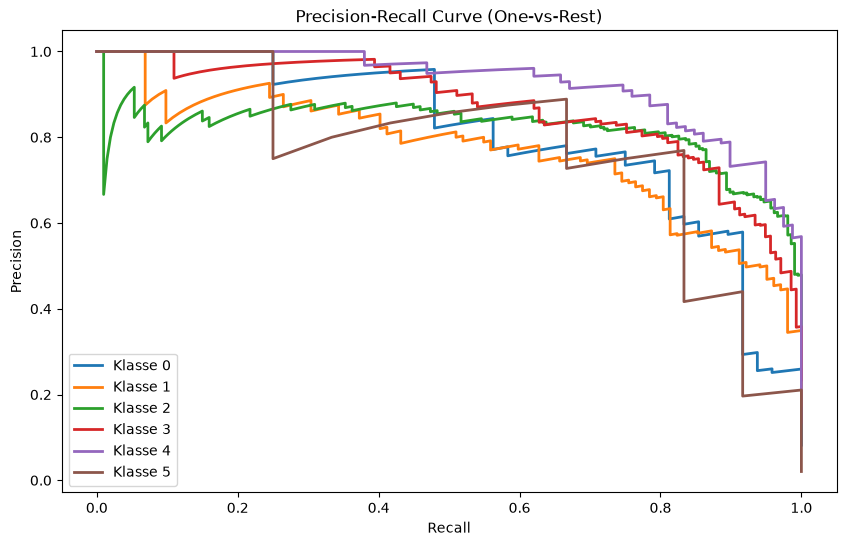

In [16]:
y_test_bin = label_binarize(y_test_20_strat, classes=labels)

best_thresholds = []

plt.figure(figsize=(10, 6))
for i in range(6):
    precision, recall, thresholds = precision_recall_curve(y_test_bin[:, i], y_pred_proba[:, i])
    plt.plot(recall, precision, lw=2, label=f'Klasse {i}')

    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
    best_thresholds.append(best_threshold)
    print(f"Klasse {i}: Bester PR-Threshold = {best_threshold:.3f}, Max F1 = {f1_scores[best_idx]:.3f}")

plt.title('Precision-Recall Curve (One-vs-Rest)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.show()

In [17]:
def objective(trial):
    params = {
        'objective': 'multi:softprob',
        'num_class': 6,
        'device': 'cuda',
        'enable_categorical': True,
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5)
    }

    model = xgb.XGBClassifier(**params, random_state=42)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(model, X_train_20_strat, y_train_20_strat, cv=cv, scoring='f1_macro', params={'sample_weight': weights_train})
    return scores.mean()

sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction='maximize', sampler=sampler)
study.optimize(objective, n_trials=30)

print("Beste Hyperparameter:", study.best_params)
print("Bester Macro F1-Score:", study.best_value)

optuna.visualization.plot_optimization_history(study).show()
optuna.visualization.plot_param_importances(study).show()

[I 2026-11-15 17:57:48,335] A new study created in memory with name: no-name-61619786-65d7-417e-b375-3f67daf358db
[I 2026-11-15 17:57:57,499] Trial 0 finished with value: 0.7360730828745752 and parameters: {'max_depth': 5, 'learning_rate': 0.22648248189516848, 'n_estimators': 380, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'gamma': 0.7799726016810132}. Best is trial 0 with value: 0.7360730828745752.
[I 2026-11-15 17:58:04,210] Trial 1 finished with value: 0.6999570129532354 and parameters: {'max_depth': 3, 'learning_rate': 0.13983740016490973, 'n_estimators': 321, 'subsample': 0.8832290311184181, 'colsample_bytree': 0.608233797718321, 'gamma': 4.8495492608099715}. Best is trial 0 with value: 0.7360730828745752.
[I 2026-11-15 17:58:17,408] Trial 2 finished with value: 0.7212714193872859 and parameters: {'max_depth': 9, 'learning_rate': 0.0033572967053517922, 'n_estimators': 132, 'subsample': 0.6733618039413735, 'colsample_bytree': 0.7216968971838151, 'gamma

Beste Hyperparameter: {'max_depth': 4, 'learning_rate': 0.17317286903496681, 'n_estimators': 136, 'subsample': 0.8413403236495332, 'colsample_bytree': 0.8157610523040385, 'gamma': 0.18677493848301924}
Bester Macro F1-Score: 0.7450872170943771


Der Tree-structured Parzen Estimator (TPESampler) ist ein Bayes'scher Optimierungsalgorithmus, der nicht blind rät (wie Random Search), sondern aus den bisherigen Evaluierungen lernt. Er modelliert die Wahrscheinlichkeit von Parametern im Verhältnis zur Performance und tastet gezielt den Suchraum ab, in dem höhere Macro-F1-Werte zu erwarten sind. Durch Anpassungen wie max_depth (Kontrolle der Modellkomplexität) und gamma (Mindest-Loss-Reduktion für einen Split) regulieren wir das Overfitting, was auf dem Trainingsdatensatz in den Plots zur Parameter-Importance deutlich sichtbar wird.

In [18]:
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer

df_l3 = train_dataset.copy()
df_l3["MS SubClass"] = df_l3["MS SubClass"].astype(str)

y_price_l3 = df_l3["SalePrice"].copy()
X_l3 = df_l3.drop(columns=["Order", "PID", "SalePrice"])

qual_map = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
qual_cols = [
    "Exter Qual", "Exter Cond", "Bsmt Qual", "Bsmt Cond",
    "Heating QC", "Kitchen Qual", "Fireplace Qu", "Garage Qual", "Garage Cond"
]
custom_ordinals = {
    "Bsmt Exposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFin Type 1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFin Type 2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "Garage Finish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Lot Shape": {"IR3": 1, "IR2": 2, "IR1": 3, "Reg": 4},
    "Land Slope": {"Sev": 1, "Mod": 2, "Gtl": 3},
    "Functional": {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4, "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8},
    "Paved Drive": {"N": 0, "P": 1, "Y": 2},
    "Central Air": {"N": 0, "Y": 1}
}

def encode_ordinals(df_in):
    df_out = df_in.copy()
    for col in qual_cols:
        df_out[col] = df_out[col].map(qual_map).fillna(0)
    for col, mapping in custom_ordinals.items():
        df_out[col] = df_out[col].map(mapping).fillna(0)
    return df_out

X_l3_ord = encode_ordinals(X_l3)

nominal_cols = X_l3_ord.select_dtypes(include=["object", "string"]).columns.tolist()
num_ord_cols = [c for c in X_l3_ord.columns if c not in nominal_cols]

preprocessor_mm = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), num_ord_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), nominal_cols)
    ]
)

X_scaled = preprocessor_mm.fit_transform(X_l3_ord)
feature_names_l3 = (
    num_ord_cols +
    preprocessor_mm.named_transformers_["cat"].get_feature_names_out(nominal_cols).tolist()
)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_names_l3)

print("Scaled feature matrix shape:", X_scaled_df.shape)

Scaled feature matrix shape: (2925, 218)


### Datenaufbereitung, kategoriale Kodierung und Min-Max-Skalierung
Ausgehend vom bereinigten Ames-Housing-Datensatz (bei dem fehlende Werte ergänzt, nahezu leere Spalten entfernt und extreme Ausreißer bei der Wohnfläche ($\ge 4.000\text{ sq. ft.}$) herausgefiltert wurde) wurden nicht-informative Identifikationsspalten (Order, PID) entfernt, damit willkürliche IDs die Abstandsberechnungen nicht verzerren können, und SalePrice wurde ausgegliedert, um die anschließende PCA und das Clustering rein unüberwacht zu halten. Kategoriale Variablen wurden anschließend entsprechend ihrer Struktur kodiert:
- Merkmale mit einem inhärenten Rang (wie „Exter Qual“ und „Kitchen Qual“) wurden mittels ordinaler Kodierung abgebildet, um ihre Qualitätshierarchie zu bewahren
- ungeordnete nominale Kategorien (wie „Neighborhood“ und „MS SubClass“) wurden mittels One-Hot-Kodierung (drop='first') transformiert, um die Einführung einer künstlichen numerischen Reihenfolge zu vermeiden. <br>
Schließlich wurden alle numerischen und ordinalen Merkmale mittels Min-Max-Skalierung auf das Intervall $[0, 1]$ umskaliert, um zu verhindern, dass Variablen mit hohen Werten wie „Lot Area“ die Varianz und die euklidischen Abstände dominieren. Die resultierende Matrixform von (2.925, 218) bestätigt, dass alle 2.925 gültigen Häuser erhalten blieben, während sich der Prädiktorraum aufgrund der für mehrkategoriale nominale Merkmale generierten binären Dummy-Variablen von 75 Rohmerkmalen auf 218 Spalten erweiterte, wodurch eine einheitlich skalierte, hochdimensionale Darstellung entstand, die für die Hauptkomponentenanalyse (PCA) bereit ist.

PC1: 13.98% (Kumulativ: 13.98%)
PC2: 9.34% (Kumulativ: 23.33%)
PC3: 5.92% (Kumulativ: 29.24%)
PC4: 4.23% (Kumulativ: 33.48%)
PC5: 3.44% (Kumulativ: 36.92%)

Erforderliche Komponenten pro Abweichungsschwelle:
  80% Varianz -> 35 Komponenten
  90% Varianz -> 58 Komponenten
  95% Varianz -> 81 Komponenten
  98% Varianz -> 114 Komponenten


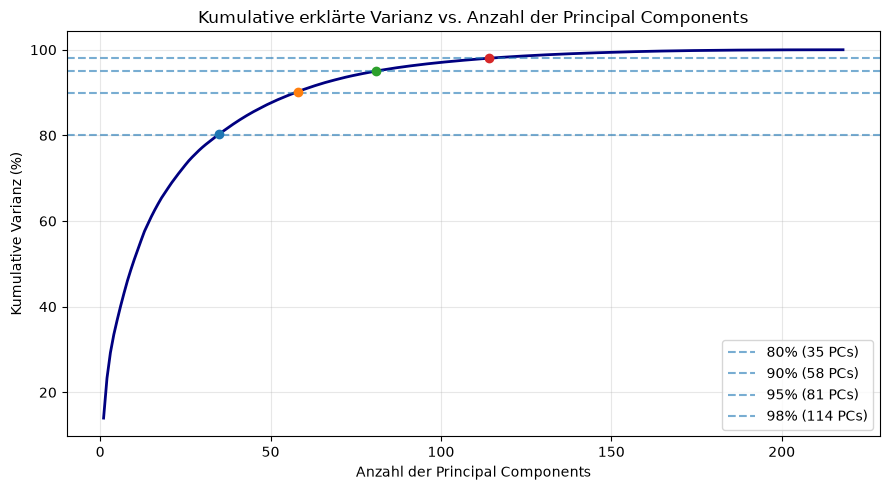

In [20]:
from sklearn.decomposition import PCA

pca_full = PCA(random_state=42)
X_pca_full = pca_full.fit_transform(X_scaled_df)

exp_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

for i in range(5):
    print(f"PC{i+1}: {exp_var[i]*100:.2f}% (Kumulativ: {cum_var[i]*100:.2f}%)")

thresholds = [0.80, 0.90, 0.95, 0.98]
n_comp_dict = {t: int(np.argmax(cum_var >= t) + 1) for t in thresholds}

print("\nErforderliche Komponenten pro Abweichungsschwelle:")
for t, n in n_comp_dict.items():
    print(f"  {int(t*100)}% Varianz -> {n} Komponenten")

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var * 100, color="navy", lw=2)
for t, n in n_comp_dict.items():
    plt.axhline(t * 100, linestyle="--", alpha=0.6, label=f"{int(t*100)}% ({n} PCs)")
    plt.scatter([n], [cum_var[n - 1] * 100], zorder=5)

plt.title("Kumulative erklärte Varianz vs. Anzahl der Principal Components")
plt.xlabel("Anzahl der Principal Components")
plt.ylabel("Kumulative Varianz (%)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### PCA und kumulative Varianzanalyse
Mithilfe der Principal Component Analysis (PCA) wurde der 218-dimensionale, Min-Max-skalierte Merkmalsraum in unkorrelierte Hauptkomponenten transformiert. Die ersten Komponenten bündeln dabei den größten Teil der Gesamtvarianz (PC1: 13,98 %, PC2: 9,34 %, PC3: 5,92 %; zusammen 36,92 % in den ersten fünf Komponenten), da viele bauliche Merkmale stark miteinander korrelieren. Um 98 % der Varianz zu erhalten, genügen 114 Komponenten (eine Reduktion um fast die Hälfte der ursprünglichen 218 Spalten). Für 95 % sind 81, für 90 % noch 58 und für 80 % lediglich 35 Komponenten erforderlich. Der flache Verlauf der kumulativen Kurve im hinteren Bereich verdeutlicht, dass viele zusätzliche Komponenten nur noch geringfügige Varianz aus seltenen One-Hot-Kategorien abbilden.

In [37]:
for i, var in enumerate(pca_full.explained_variance_ratio_[:10], start=1):
    print(f"PC{i:2d}: {var*100:.2f}%")

PC 1: 13.98%
PC 2: 9.34%
PC 3: 5.92%
PC 4: 4.23%
PC 5: 3.44%
PC 6: 3.23%
PC 7: 3.02%
PC 8: 2.87%
PC 9: 2.57%
PC10: 2.39%


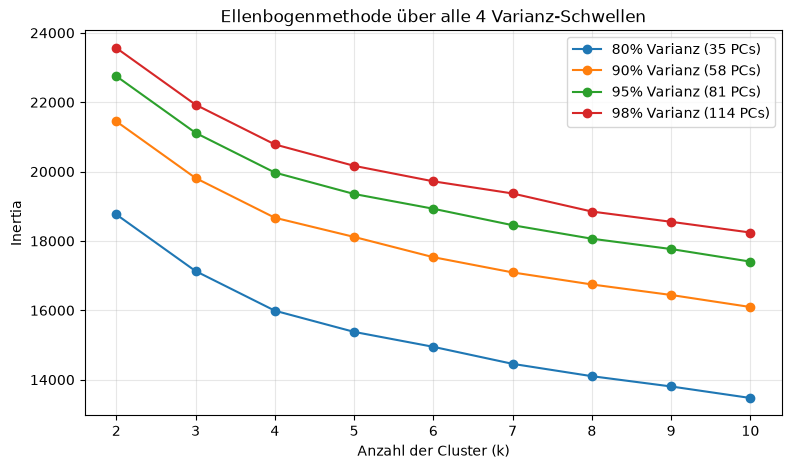

In [21]:
from sklearn.cluster import KMeans

pca_datasets = {t: X_pca_full[:, :n] for t, n in n_comp_dict.items()}

k_range = range(2, 11)
plt.figure(figsize=(9, 5))

for t, X_red in pca_datasets.items():
    inertias = []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=10, random_state=42)
        km.fit(X_red)
        inertias.append(km.inertia_)
    plt.plot(k_range, inertias, marker="o", label=f"{int(t*100)}% Varianz ({X_red.shape[1]} PCs)")

plt.title("Ellenbogenmethode über alle 4 Varianz-Schwellen")
plt.xlabel("Anzahl der Cluster (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_range))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

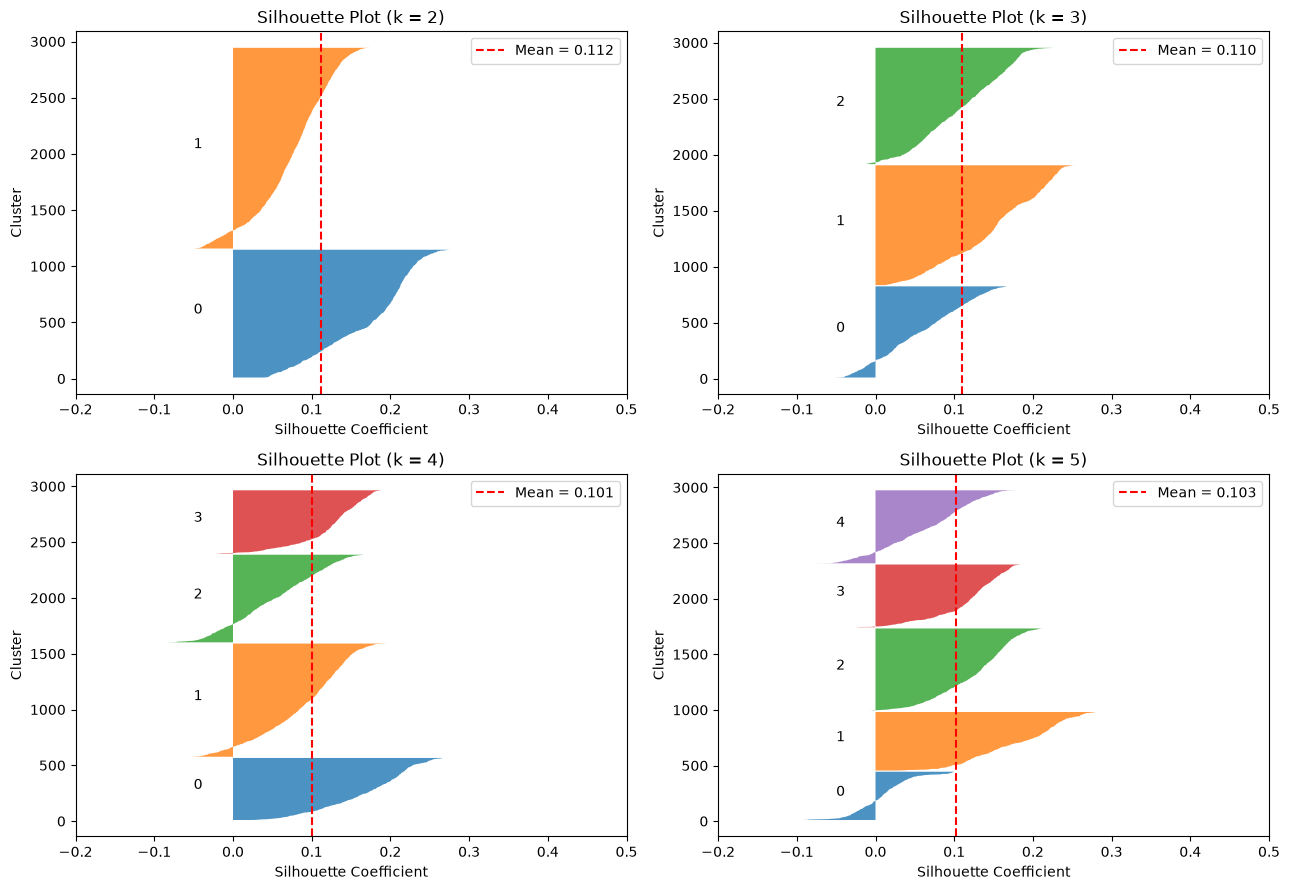

In [22]:
from sklearn.metrics import silhouette_score, silhouette_samples

X_98 = pca_datasets[0.98]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for idx, k in enumerate([2, 3, 4, 5]):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_98)
    sil_avg = silhouette_score(X_98, labels)
    sample_vals = silhouette_samples(X_98, labels)

    y_lower = 10
    for i in range(k):
        ith_vals = np.sort(sample_vals[labels == i])
        y_upper = y_lower + len(ith_vals)
        axes[idx].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_vals, alpha=0.8)
        axes[idx].text(-0.05, y_lower + 0.5 * len(ith_vals), str(i))
        y_lower = y_upper + 10

    axes[idx].axvline(sil_avg, color="red", linestyle="--", label=f"Mean = {sil_avg:.3f}")
    axes[idx].set_title(f"Silhouette Plot (k = {k})")
    axes[idx].set_xlabel("Silhouette Coefficient")
    axes[idx].set_ylabel("Cluster")
    axes[idx].set_xlim([-0.2, 0.5])
    axes[idx].legend()

plt.tight_layout()
plt.show()

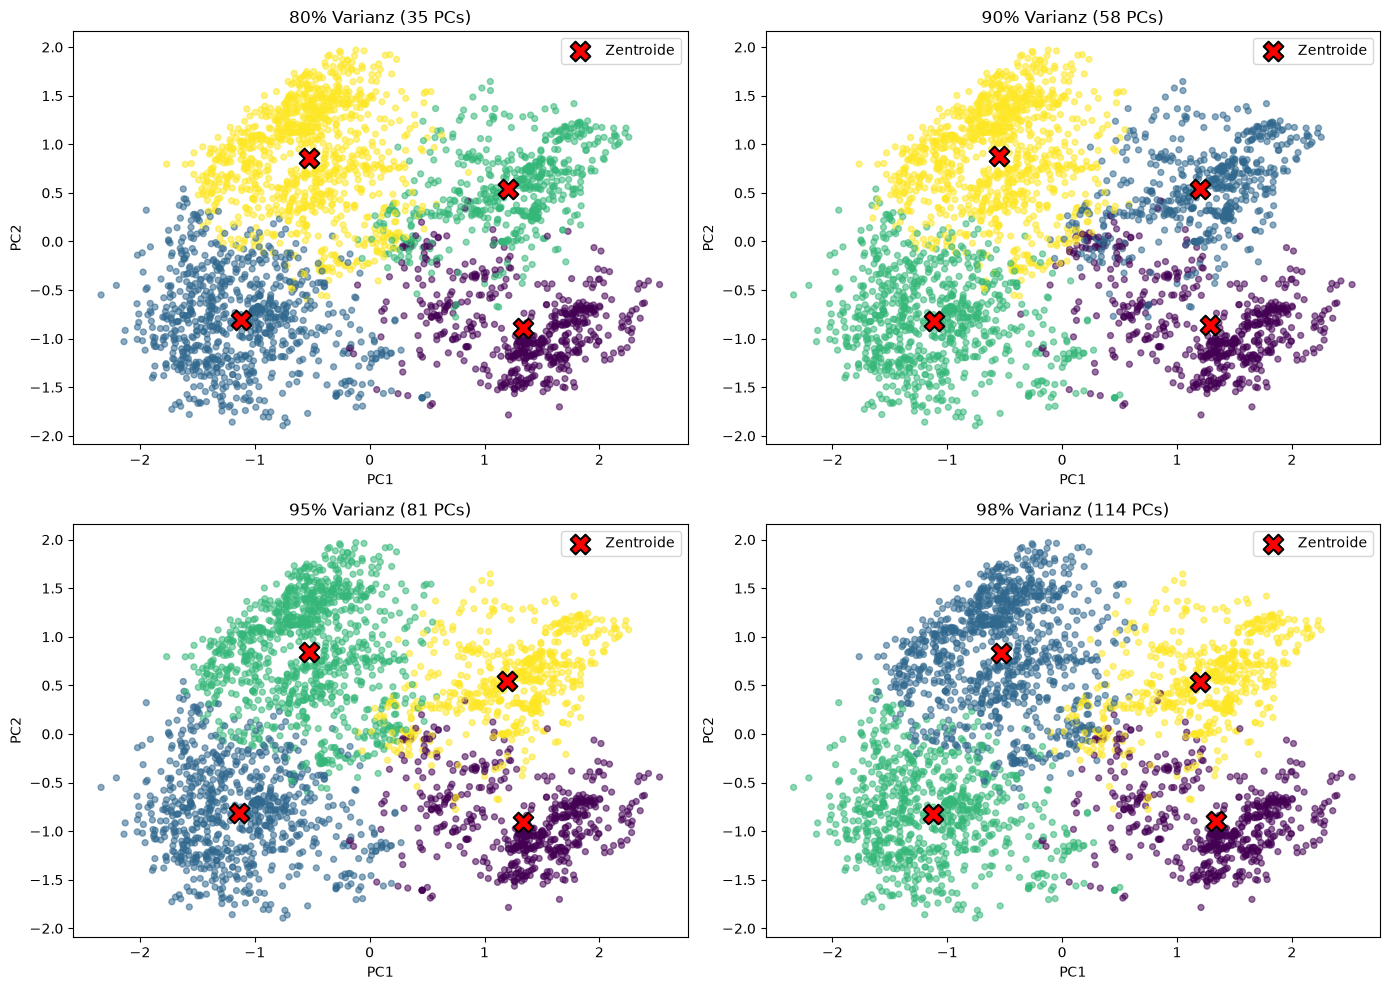

In [23]:
k_chosen = 4
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
kmeans_models = {}

for idx, (t, X_red) in enumerate(pca_datasets.items()):
    km = KMeans(n_clusters=k_chosen, n_init=10, random_state=42)
    labels = km.fit_predict(X_red)
    kmeans_models[t] = km
    centroids = km.cluster_centers_

    axes[idx].scatter(X_red[:, 0], X_red[:, 1], c=labels, cmap="viridis", alpha=0.55, s=18)
    axes[idx].scatter(
        centroids[:, 0], centroids[:, 1],
        marker="X", s=200, c="red", edgecolor="black", lw=1.5, label="Zentroide"
    )
    axes[idx].set_title(f"{int(t*100)}% Varianz ({X_red.shape[1]} PCs)")
    axes[idx].set_xlabel("PC1")
    axes[idx].set_ylabel("PC2")
    axes[idx].legend()

plt.tight_layout()
plt.show()

In [25]:
df_clusters = df_l3.copy()
df_clusters["Cluster"] = kmeans_models[0.98].labels_

summary_cols = [
    "Year Built", "Overall Qual", "Gr Liv Area",
    "Total Bsmt SF", "Garage Cars", "Full Bath", "SalePrice"
]

cluster_profile = df_clusters.groupby("Cluster")[summary_cols].mean().round(1)
cluster_profile["Count"] = df_clusters["Cluster"].value_counts()
print(cluster_profile)

         Year Built  Overall Qual  Gr Liv Area  Total Bsmt SF  Garage Cars  \
Cluster                                                                      
0            1998.2           7.1       1969.9          997.4          2.3   
1            1965.6           5.5       1317.4         1057.5          1.6   
2            1937.1           5.2       1362.9          739.3          1.2   
3            2002.4           7.4       1524.3         1501.0          2.3   

         Full Bath  SalePrice  Count  
Cluster                               
0              2.0   240565.6    557  
1              1.3   154404.6   1015  
2              1.3   125702.4    786  
3              1.8   243714.3    567  


### Interpretation der Cluster und Vergleich der Varianz-Schwellen
Der Vergleich der PC1-PC2-Projektionen über alle vier Varianz-Schwellen (80%, 90%, 95%, 98%) zeigt nahezu identische Cluster-Zentroide und Punktzuordnungen; lediglich vereinzelte Grenzpunkte nahe dem Ursprung wechseln bei höherer Dimensionszahl das Cluster. Dies bestätigt, dass bereits 35 Hauptkomponenten (80 % Varianz) die wesentliche Struktur des Datensatzes abbilden.Die inhaltliche Auswertung der unskalierten Merkmale für $k = 4$ zeigt vier klar interpretierbare Gebäudetypen, die auch ohne Verwendung von SalePrice deutlich getrennte Preissegmente abbilden:
- Cluster 2 (Altbauten, Ø Baujahr 1937): Niedrigste Bauqualität (5,2), kleine Keller-/Garagenflächen und geringster Durchschnittspreis (~125.700 USD).
- Cluster 1 (Bestandsbauten der 1960er, Ø Baujahr 1966): Mittlere Qualität (5,5) und moderates Preissegment (~154.400 USD).
- Cluster 3 (Moderne 1-geschossige Bungalows/Ranches, Ø Baujahr 2002): Hohe Qualität (7,4), Wohnfläche entspricht nahezu der Kellerfläche (~1.524 vs. ~1.501 sq ft), höchstes Preissegment (~243.700 USD).
- Cluster 0 (Moderne 2-geschossige Einfamilienhäuser, Ø Baujahr 1998): Hohe Qualität (7,1), Wohnfläche etwa doppelt so groß wie die Kellerfläche (~1.970 vs. ~997 sq ft), ebenfalls oberes Preissegment (~240.600 USD).

Min-Max (Original)         -> PC1: 15.16% | 90% Var: 71 PCs | 98% Var: 135 PCs
StandardScaler (Z-Score)   -> PC1: 6.31% | 90% Var: 154 PCs | 98% Var: 203 PCs
Log1p + Min-Max            -> PC1: 14.84% | 90% Var: 73 PCs | 98% Var: 136 PCs


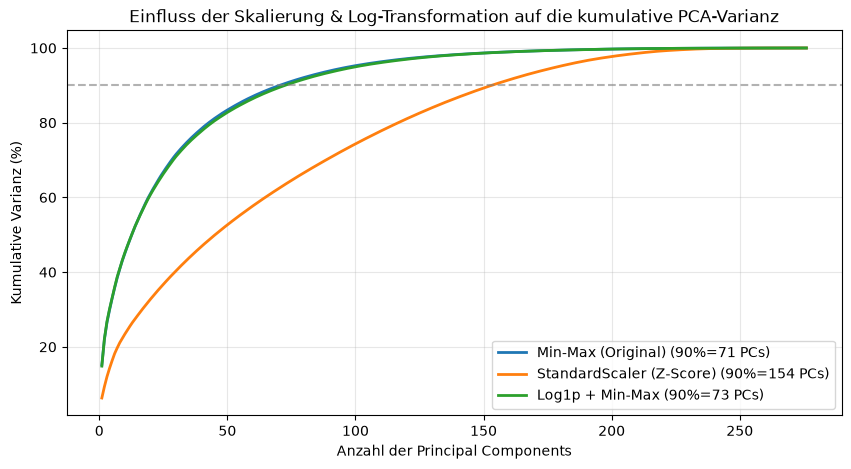

In [26]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

X_raw = df_l3.drop(columns=["SalePrice"], errors="ignore").copy()

num_cols = X_raw.select_dtypes(include=[np.number]).columns
skewed_cols = [c for c in num_cols if X_raw[c].skew() > 0.75 and (X_raw[c] >= 0).all()]

X_log = X_raw.copy()
X_log[skewed_cols] = np.log1p(X_log[skewed_cols])

X_enc = pd.get_dummies(X_raw, drop_first=True)
X_log_enc = pd.get_dummies(X_log, drop_first=True)

scalers = {
    "Min-Max (Original)": MinMaxScaler().fit_transform(X_enc),
    "StandardScaler (Z-Score)": StandardScaler().fit_transform(X_enc),
    "Log1p + Min-Max": MinMaxScaler().fit_transform(X_log_enc),
}

plt.figure(figsize=(10, 5))
for name, X_mat in scalers.items():
    pca_tmp = PCA(random_state=42).fit(X_mat)
    cum_v = np.cumsum(pca_tmp.explained_variance_ratio_) * 100
    n_90 = np.argmax(cum_v >= 90) + 1
    n_98 = np.argmax(cum_v >= 98) + 1
    print(f"{name:26s} -> PC1: {pca_tmp.explained_variance_ratio_[0]*100:.2f}% | 90% Var: {n_90} PCs | 98% Var: {n_98} PCs")
    plt.plot(range(1, len(cum_v) + 1), cum_v, lw=2, label=f"{name} (90%={n_90} PCs)")

plt.axhline(90, color="gray", linestyle="--", alpha=0.6)
plt.title("Einfluss der Skalierung & Log-Transformation auf die kumulative PCA-Varianz")
plt.xlabel("Anzahl der Principal Components")
plt.ylabel("Kumulative Varianz (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Vergleich von Skalierungsmethoden und Log-Transformation
Der Vergleich zeigt einen deutlichen Unterschied zwischen Min-Max-Skalierung und Z-Score-Standardisierung (StandardScaler): Während bei Min-Max bereits 71 Komponenten für 90 % Varianz ausreichen (PC1 = 15,16 %), benötigt der StandardScaler 154 Komponenten (PC1 = 6,31 %). Grund dafür ist, dass der StandardScaler alle Spalten auf Varianz $1$ normiert – dadurch erhalten seltene binäre One-Hot-Kategorien dasselbe Gewicht wie zentrale Merkmale, was das Rauschen im Merkmalsraum erhöht und die Komprimierbarkeit durch PCA verschlechtert.
<br> Das Logarithmieren (log1p) rechtsschiefer numerischer Merkmale (z. B. Lot Area, Gr Liv Area) in Kombination mit Min-Max verändert die Varianzkurve kaum (PC1 = 14,84 %, 73 Komponenten für 90 % Varianz), da binäre 0/1-Spalten weiterhin die Gesamtvarianz dominieren. Dennoch glättet log1p extreme Ausreißer bei Flächenmaßen, sodass normale Unterschiede zwischen Häusern im Intervall $[0, 1]$ besser aufgelöst werden.

In [38]:
print("\n--- k-Means Vergleich nach Skalierung (k=4, 98% Varianz) ---")
for name, X_mat in scalers.items():
    pca_tmp = PCA(n_components=0.98, random_state=42).fit_transform(X_mat)
    km_tmp = KMeans(n_clusters=4, n_init=10, random_state=42).fit(pca_tmp)
    sil = silhouette_score(pca_tmp, km_tmp.labels_)
    counts = np.bincount(km_tmp.labels_)
    print(f"{name:26s} -> PCs: {pca_tmp.shape[1]:3d} | Silhouette: {sil:.3f} | Cluster-Größen: {counts}")


--- k-Means Vergleich nach Skalierung (k=4, 98% Varianz) ---
Min-Max (Original)         -> PCs: 135 | Silhouette: 0.078 | Cluster-Größen: [601 976 759 589]
StandardScaler (Z-Score)   -> PCs: 203 | Silhouette: 0.039 | Cluster-Größen: [ 159 1099  683  984]
Log1p + Min-Max            -> PCs: 136 | Silhouette: 0.080 | Cluster-Größen: [596 591 964 774]


### Auswirkung auf das k-Means-Clustering ($k = 4$, 98 % Varianz)
Auch im Clustering selbst schneidet die Min-Max-Skalierung deutlich besser ab als der StandardScaler: Der Silhouette-Score halbiert sich beim StandardScaler von 0,078 auf 0,039, und es entsteht ein stark unausgewogenes Nischen-Cluster mit nur 159 Häusern, da seltene One-Hot-Kategorien über 203 Dimensionen hinweg die euklidischen Distanzen verzerren. Die Kombination Log1p + Min-Max erreicht mit 0,080 den höchsten Silhouette-Score bei weiterhin stabilen, ausgewogenen Clustergrößen (596, 591, 964, 774), da extreme Flächenausreißer geglättet werden.

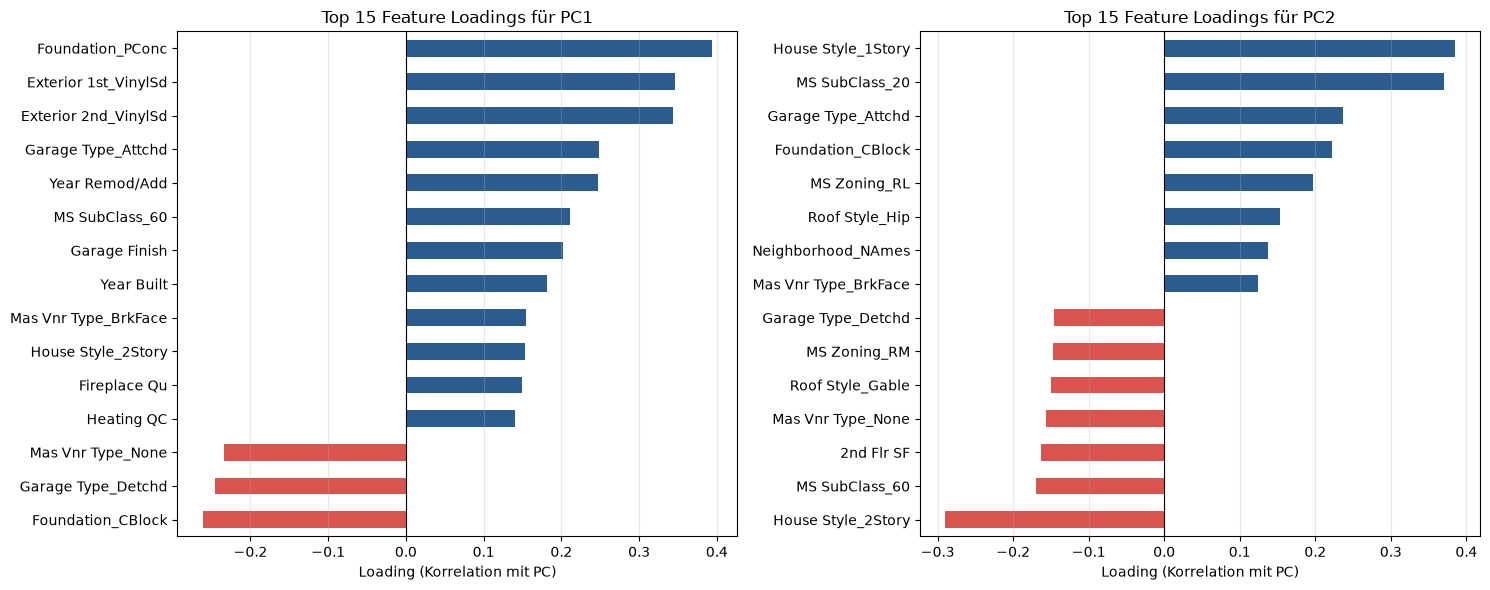

In [39]:
loadings = pca_full.components_.T * np.sqrt(pca_full.explained_variance_)
loadings_df = pd.DataFrame(
    loadings,
    index=X_scaled_df.columns,
    columns=[f"PC{i+1}" for i in range(loadings.shape[1])]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for idx, pc in enumerate(["PC1", "PC2"]):
    top_features = loadings_df[pc].abs().sort_values(ascending=False).head(15).index
    vals = loadings_df.loc[top_features, pc].sort_values()

    colors = ["#d9534f" if v < 0 else "#2b5c8f" for v in vals]
    vals.plot(kind="barh", ax=axes[idx], color=colors)
    axes[idx].axvline(0, color="black", linewidth=0.8)
    axes[idx].set_title(f"Top 15 Feature Loadings für {pc}")
    axes[idx].set_xlabel("Loading (Korrelation mit PC)")
    axes[idx].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Analyse der Feature Loadings (PC1 und PC2)
Die grafische Auswertung der Loadings verdeutlicht, welche Merkmale die ersten beiden Hauptkomponenten bestimmen:   PC1 (Bauweise und Modernität):
- Positive Loadings werden durch moderne Baumerkmale wie gegossene Betonfundamente (Foundation_PConc), Vinyl-Fassaden (Exterior 1st/2nd_VinylSd), integrierte Garagen (Garage Type_Attchd) sowie neuere Bau- und Renovierungsjahre (Year Built, Year Remod/Add) dominiert.
- Negative Loadings stehen für ältere Bauweisen mit Hohlblockstein-Fundamenten (Foundation_CBlock) und freistehenden Garagen (Garage Type_Detchd).   PC2 (Geschossigkeit / Gebäudetyp): PC2 trennt eingeschossige Bungalows (House Style_1Story, MS SubClass_20 im positiven Bereich) klar von zweigeschossigen Häusern (House Style_2Story, MS SubClass_60, 2nd Flr SF im negativen Bereich).
<br>Auffällig ist zudem, dass binäre One-Hot-Merkmale die höchsten Loadings aufweisen, da sie durch die Min-Max-Skalierung die Extremwerte $0$ und $1$ annehmen.

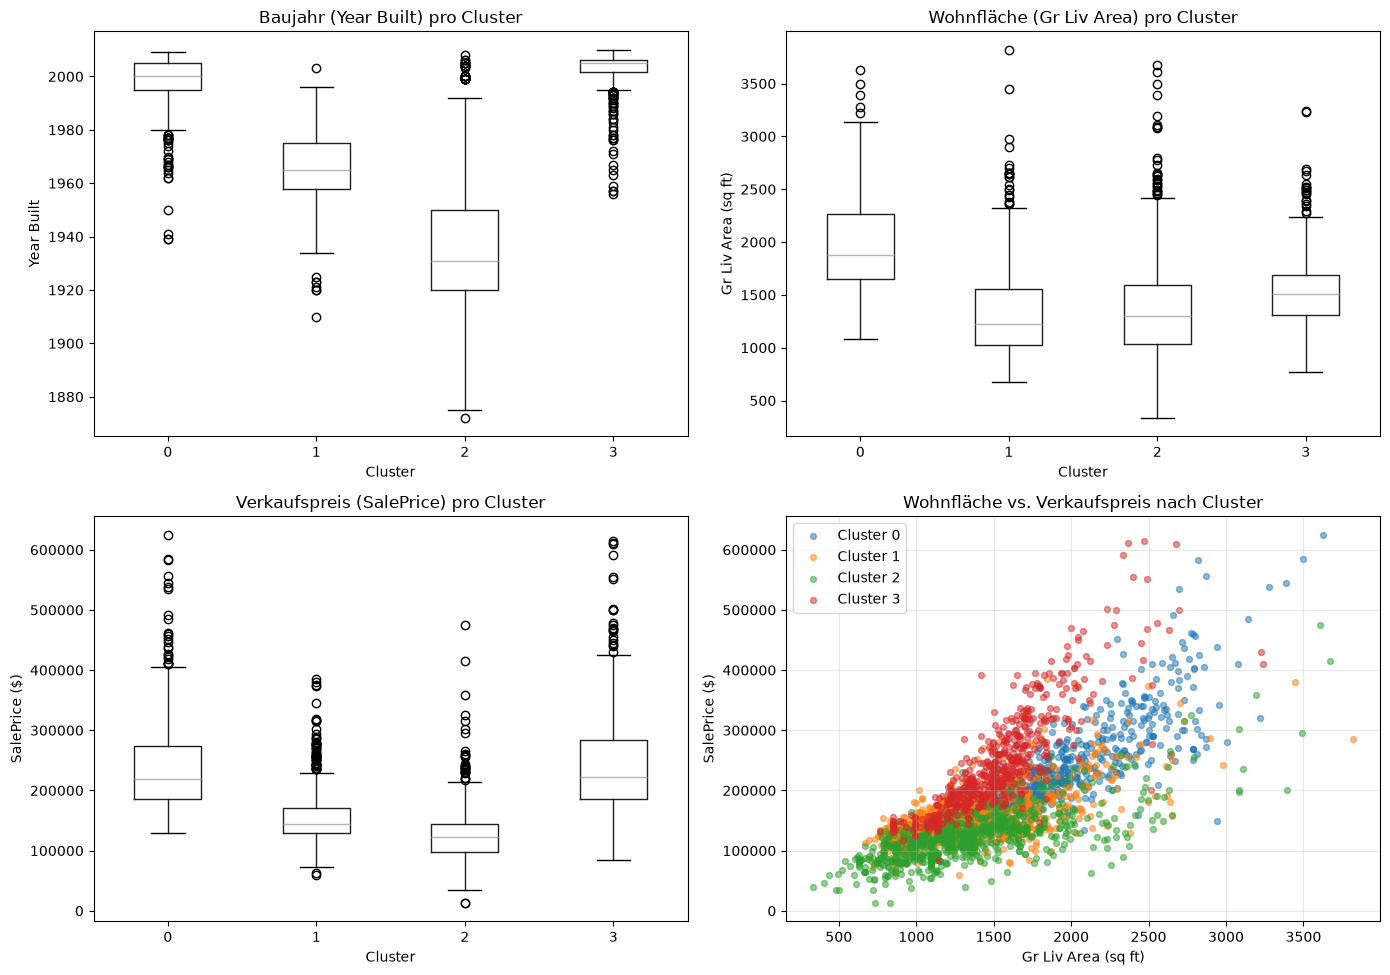

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df_clusters.boxplot(column="Year Built", by="Cluster", ax=axes[0, 0], grid=False)
axes[0, 0].set_title("Baujahr (Year Built) pro Cluster")
axes[0, 0].set_xlabel("Cluster")
axes[0, 0].set_ylabel("Year Built")

df_clusters.boxplot(column="Gr Liv Area", by="Cluster", ax=axes[0, 1], grid=False)
axes[0, 1].set_title("Wohnfläche (Gr Liv Area) pro Cluster")
axes[0, 1].set_xlabel("Cluster")
axes[0, 1].set_ylabel("Gr Liv Area (sq ft)")

df_clusters.boxplot(column="SalePrice", by="Cluster", ax=axes[1, 0], grid=False)
axes[1, 0].set_title("Verkaufspreis (SalePrice) pro Cluster")
axes[1, 0].set_xlabel("Cluster")
axes[1, 0].set_ylabel("SalePrice ($)")

for c in sorted(df_clusters["Cluster"].unique()):
    sub = df_clusters[df_clusters["Cluster"] == c]
    axes[1, 1].scatter(sub["Gr Liv Area"], sub["SalePrice"], alpha=0.5, s=18, label=f"Cluster {c}")

axes[1, 1].set_title("Wohnfläche vs. Verkaufspreis nach Cluster")
axes[1, 1].set_xlabel("Gr Liv Area (sq ft)")
axes[1, 1].set_ylabel("SalePrice ($)")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.suptitle("")
plt.tight_layout()
plt.show()

### Inhaltliche Beschreibung der Cluster (anhand der Visualisierungen aus Aufgabe 1)
- Cluster 0 (Moderne, große 2-geschossige Häuser): Baujahr überwiegend zwischen 1995 und 2005, größte Wohnfläche aller Gruppen (Median ~1.880 sq ft) und oberes Preissegment (Median ~220.000 USD).
- Cluster 1 (Kompakte 1960er-Bestandsbauten): Konzentriert auf Baujahre um 1958–1975 mit kompakter Wohnfläche (Median ~1.230 sq ft) und moderatem Verkaufspreis (Median ~145.000 USD).
- Cluster 2 (Ältere Vorkriegs- und Nachkriegsbauten): Älteste Bausubstanz (Median ~1931, Box von 1920 bis 1950) und niedrigstes Preisniveau (Median ~123.000 USD).
- Cluster 3 (Moderne 1-geschossige Bungalows / Ranches): Jüngste Baujahre (Median ~2004), mittelgroße Wohnfläche (Median ~1.500 sq ft), aber höchster Quadratmeterpreis im Streudiagramm (Median ~225.000 USD).

In [41]:
X_template = df_l3.drop(columns=["Order", "PID", "SalePrice"], errors="ignore")
baseline = {
    col: X_template[col].median() if pd.api.types.is_numeric_dtype(X_template[col]) else X_template[col].mode()[0]
    for col in X_template.columns
}

synthetic_specs = {
    "Haus A (Moderner Bungalow 2006)": {
        "Year Built": 2006, "Year Remod/Add": 2006, "Overall Qual": 8,
        "Gr Liv Area": 1600, "1st Flr SF": 1600, "2nd Flr SF": 0, "Total Bsmt SF": 1580,
        "House Style": "1Story", "MS SubClass": "20", "Foundation": "PConc",
        "Garage Type": "Attchd", "Garage Cars": 2, "Full Bath": 2
    },
    "Haus B (Modernes 2-Geschosser 2004)": {
        "Year Built": 2004, "Year Remod/Add": 2005, "Overall Qual": 8,
        "Gr Liv Area": 2200, "1st Flr SF": 1100, "2nd Flr SF": 1100, "Total Bsmt SF": 1100,
        "House Style": "2Story", "MS SubClass": "60", "Foundation": "PConc",
        "Garage Type": "Attchd", "Garage Cars": 3, "Full Bath": 2
    },
    "Haus C (60er-Jahre Bestandsbau 1964)": {
        "Year Built": 1964, "Year Remod/Add": 1964, "Overall Qual": 5,
        "Gr Liv Area": 1200, "1st Flr SF": 1200, "2nd Flr SF": 0, "Total Bsmt SF": 1050,
        "House Style": "1Story", "MS SubClass": "20", "Foundation": "CBlock",
        "Garage Type": "Attchd", "Garage Cars": 1, "Full Bath": 1
    },
    "Haus D (Vorkriegs-Altbau 1925)": {
        "Year Built": 1925, "Year Remod/Add": 1950, "Overall Qual": 5,
        "Gr Liv Area": 1350, "1st Flr SF": 800, "2nd Flr SF": 550, "Total Bsmt SF": 700,
        "House Style": "1.5Fin", "MS SubClass": "50", "Foundation": "BrkTil",
        "Garage Type": "Detchd", "Garage Cars": 1, "Full Bath": 1
    }
}

new_houses_df = pd.DataFrame(
    [{**baseline, **specs} for specs in synthetic_specs.values()],
    index=synthetic_specs.keys()
)
new_houses_df["MS SubClass"] = new_houses_df["MS SubClass"].astype(str)

new_houses_ord = encode_ordinals(new_houses_df)
new_scaled = preprocessor_mm.transform(new_houses_ord)
new_scaled_df = pd.DataFrame(new_scaled, columns=feature_names_l3, index=new_houses_df.index)

n_98 = n_comp_dict[0.98]
new_pca = pca_full.transform(new_scaled_df)[:, :n_98]
pred_clusters = kmeans_models[0.98].predict(new_pca)

for name, cl in zip(new_houses_df.index, pred_clusters):
    print(f"{name:38s} -> Zugeordnet zu Cluster {cl}")

Haus A (Moderner Bungalow 2006)        -> Zugeordnet zu Cluster 3
Haus B (Modernes 2-Geschosser 2004)    -> Zugeordnet zu Cluster 0
Haus C (60er-Jahre Bestandsbau 1964)   -> Zugeordnet zu Cluster 1
Haus D (Vorkriegs-Altbau 1925)         -> Zugeordnet zu Cluster 2


### Inferenz auf neuen, synthetischen Häusern
Alle vier erfundenen Häuser werden intuitiv exakt den erwarteten Clustern zugeordnet:
- Haus A (Moderner Bungalow, Baujahr 2006) $\rightarrow$ Cluster 3: Passt präzise zum Cluster der modernen eingeschossigen Häuser (Ø Baujahr ~2002, hohe Bauqualität, Betonfundament).
- Haus B (Modernes 2-Geschosser, Baujahr 2004) $\rightarrow$ Cluster 0: Wird korrekt den großen, modernen zweigeschossigen Einfamilienhäusern zugeordnet.
- Haus C (60er-Jahre Bestandsbau, Baujahr 1964) $\rightarrow$ Cluster 1: Landet im Cluster der Bestandsbauten aus den 1960er-Jahren (Ø Baujahr ~1966, Hohlblockstein-Fundament).
- Haus D (Vorkriegs-Altbau, Baujahr 1925) $\rightarrow$ Cluster 2: Wird eindeutig der Gruppe älterer Vorkriegs- und Nachkriegsbauten (Ø Baujahr ~1937, freistehende Garage) zugewiesen.
#### Warum muss vor der Inferenz mit PCA transformiert werden?
- Gleiches Koordinatensystem: Die Zentroide des k-Means-Modells wurden nicht im ursprünglichen 218-dimensionalen Merkmalsraum berechnet, sondern im rotierten, orthogonalen Koordinatensystem der Hauptkomponenten (PC1, PC2, …). Durch pca.transform() (ohne erneutes fit) wird der neue Datenpunkt mit denselben gelernten Gewichtungen auf genau diese Achsen projiziert.
- Identische Dimensionalität: Das k-Means-Modell erwartet exakt 114 Features (98 % Varianzschwelle). Ohne die PCA-Projektion und Dimensionsreduktion von 218 auf 114 Merkmale ließen sich keine euklidischen Distanzen zu den Zentroiden berechnen.

In [34]:
import plotly.graph_objects as go

cluster_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for t, km in kmeans_models.items():
    X_red = pca_datasets[t]
    labels = km.labels_
    centroids = km.cluster_centers_

    fig = go.Figure()

    for c in range(km.n_clusters):
        mask = labels == c
        fig.add_trace(go.Scatter3d(
            x=X_red[mask, 0],
            y=X_red[mask, 1],
            z=X_red[mask, 2],
            mode="markers",
            name=f"Cluster {c} (n={mask.sum()})",
            marker=dict(
                size=3.5,
                color=cluster_colors[c % len(cluster_colors)],
                opacity=0.65
            )
        ))

    fig.add_trace(go.Scatter3d(
        x=centroids[:, 0],
        y=centroids[:, 1],
        z=centroids[:, 2],
        mode="markers+text",
        name="Zentroide",
        text=[f"Z{c}" for c in range(km.n_clusters)],
        textposition="top center",
        marker=dict(
            size=9,
            color="black",
            symbol="diamond",
            line=dict(color="white", width=1.5)
        )
    ))

    fig.update_layout(
        title=f"Interaktiver 3D-PCA-Plot (PC1–PC3) | {int(t*100)}% Varianz ({X_red.shape[1]} PCs, k={km.n_clusters})",
        scene=dict(
            xaxis_title="PC1 (Modernität / Bauqualität)",
            yaxis_title="PC2 (1- vs. 2-Geschosser)",
            zaxis_title="PC3"
        ),
        width=850,
        height=650,
        margin=dict(l=0, r=0, b=0, t=45)
    )
    fig.show()

### Auswertung Bonus a (3D-Visualisierung & Eignung von k-Means)

- Zusätzliche Muster in 3D (PC3): Durch die dritte Hauptkomponente (PC3) wird die räumliche Tiefe der Punktwolke sichtbar: Punkte, die in der 2D-Projektion nahe beieinander lagen, fächern sich entlang von PC3 nach weiteren baulichen Details (z. B. Kellergröße/-ausbau, 1,5-geschossige Zwischenformen und Ausreißer im Luxussegment) auf. Über alle vier Varianz-Schwellen (80 %–98 %) bleiben die 3D-Zentroide nahezu identisch.

- Interpretation: Die Häuser bilden keine scharf getrennten Inseln, sondern eine zusammenhängende, kontinuierliche Punktwolke, da sich Baujahre und Ausstattungen fließend verändern. k-Means teilt diesen Raum in vier gut interpretierbare Marktsegmente auf.

- Ist k-Means passend oder wäre eine andere Methode besser? k-Means liefert eine solide, schnelle Basis-Segmentierung, stößt hier aber an Grenzen: Es setzt kugelförmige, gleich große Cluster mit harten Trenngrenzen voraus, obwohl die Datenwolke elliptisch verzerrt ist und fließende Übergänge besitzt (niedriger Silhouette-Score von ~0,10). Besser geeignet wären Gaussian Mixture Models (GMM), da sie elliptische Cluster (unterschiedliche Kovarianzen entlang der PCs) erlauben und weiche Wahrscheinlichkeitszuordnungen für renovierte Übergangshäuser liefern. Dichtebasierte Verfahren wie DBSCAN wären hingegen ungeeignet, da keine leeren Dichtelücken zwischen den Segmenten existieren.

In [42]:
bins = [0, 100000, 130000, 180000, 250000, 400000, np.inf]
price_labels = [
    "Klasse 0 (< 100k $)",
    "Klasse 1 (100k–130k $)",
    "Klasse 2 (130k–180k $)",
    "Klasse 3 (180k–250k $)",
    "Klasse 4 (250k–400k $)",
    "Klasse 5 (≥ 400k $)"
]
price_cats = pd.cut(df_l3["SalePrice"], bins=bins, labels=price_labels, right=False)

price_colors = {
    "Klasse 0 (< 100k $)": "#d62728",      # Rot
    "Klasse 1 (100k–130k $)": "#ff7f0e",   # Orange
    "Klasse 2 (130k–180k $)": "#f1c40f",   # Gelb
    "Klasse 3 (180k–250k $)": "#17becf",   # Cyan / Türkis
    "Klasse 4 (250k–400k $)": "#2ca02c",   # Grün
    "Klasse 5 (≥ 400k $)": "#1f77b4"       # Blau
}

X_98 = pca_datasets[0.98]
fig_price = go.Figure()

for cat in price_labels:
    mask = (price_cats == cat).values
    fig_price.add_trace(go.Scatter3d(
        x=X_98[mask, 0],
        y=X_98[mask, 1],
        z=X_98[mask, 2],
        mode="markers",
        name=f"{cat} (n={mask.sum()})",
        marker=dict(
            size=3.5,
            color=price_colors[cat],
            opacity=0.7
        )
    ))

fig_price.update_layout(
    title="Interaktiver 3D-PCA-Plot (PC1–PC3) gefärbt nach den 6 Preiskategorien",
    scene=dict(
        xaxis_title="PC1 (Modernität / Bauqualität)",
        yaxis_title="PC2 (1- vs. 2-Geschosser)",
        zaxis_title="PC3"
    ),
    width=850,
    height=650,
    margin=dict(l=0, r=0, b=0, t=45)
)
fig_price.show()

### Auswertung Bonus b (Vergleich der 6 Preiskategorien mit den 4 k-Means-Clustern)
- Beobachtung im 3D-Plot: Die sechs Preisklassen bilden keinen scharf abgegrenzten Raum, sondern einen kontinuierlichen Farbverlauf entlang von PC1 (von Rot/Orange im negativen Bereich über Gelb/Türkis bis zu Grün und Blau im positiven Bereich), wobei benachbarte Preisklassen stark überlappen. Entlang von PC2 erstrecken sich die teuersten Klassen (Blau und Grün) sowohl über den oberen als auch über den unteren Bereich.
- Vergleich mit den 4 Clustern: Entlang von PC1 stimmen beide Einteilungen gut überein (ältere, günstige Häuser in Cluster 1 und 2 vs. moderne, teure Häuser in Cluster 0 und 3). Der entscheidende Unterschied liegt entlang von PC2: Während die Preisklassen moderne 1- und 2-Geschosser gemeinsam in die oberen Preiskategorien (Blau/Grün) einordnen, trennt k-Means diese genau entlang von PC2 in Cluster 3 (moderne 1-Geschosser) und Cluster 0 (moderne 2-Geschosser), obwohl beide nahezu denselben Durchschnittspreis (~244.000 USD vs. ~241.000 USD) erzielen.
- Erklärung über Feature Importance und PCA-Zusammensetzung:
  1. Unüberwacht vs. Überwacht: PCA und k-Means erhielten SalePrice nicht als Eingabe und gruppieren rein nach struktureller Merkmalsvarianz, während die Preisklassen direkt auf der Zielvariable SalePrice basieren.
  2.  Zusammensetzung der PCs: PC1 bündelt Baujahr, Fundamenttyp (Foundation_PConc) und Bauqualität – Merkmale, die gleichzeitig eine sehr hohe Feature Importance für den Verkaufspreis besitzen, weshalb der Preisverlauf PC1 folgt. PC2 hingegen wird von der Geschossigkeit (House Style_1Story vs. 2Story) dominiert: Dieses Merkmal erzeugt zwar viel Varianz im Datensatz, hat aber eine geringe Preis-Differenzierung. Umgekehrt sind wichtige kontinuierliche Preistreiber wie die genaue Wohnfläche (Gr Liv Area) durch die Min-Max-Skalierung komprimiert und auf höhere Komponenten (PC3–PC114) verteilt, sodass sich die 6 Preisstufen in den ersten drei PCs überlappen.